# T21. Matrices origen–destino por zonas administrativas

**Qué queremos ver.** Cuántos viajes de Helbiz conectan los municipios (*Municipi*) y las zonas urbanísticas de Roma en febrero de 2021, en el periodo de ajuste y en la semana reservada.

**Por qué importa.** Los municipios permiten interpretar el alcance territorial de los flujos. Las zonas urbanísticas muestran conexiones que se agregan en el nivel municipal. Comparamos ambos con H3 de resolución 8 sobre los mismos viajes para ver cuánto depende el porcentaje intrazonal de la división elegida.

Fuente cartográfica Istat, *Basi territoriali e variabili censuarie*, áreas subcomunales de 2021, CC BY 4.0. La foto territorial es del 31/12/2021 y se usa como referencia para todo febrero. El ZIP original y su ficha quedan archivados para repetir el análisis sin conexión. [Catálogo de Istat](https://www.istat.it/notizia/basi-territoriali-e-variabili-censuarie/) · [Licencia de los datos](https://www.istat.it/dati/open-data/)

## 1. Asignación de orígenes y destinos

**Qué queremos ver.** En qué polígono cae cada extremo de los viajes elegibles. Usamos el nivel ASC1 para municipios y ASC3 para zonas urbanísticas, filtrados por el código de Roma (58091).

**Por qué importa.** Las áreas que no están en la cartografía y los puntos con más de un polígono posible deben quedar contabilizados para que la matriz concilie con el total.

In [1]:
import json

import geopandas as gpd
import h3
import numpy as np
import pandas as pd
from IPython.display import display

from comun.config import cargar_config, carpeta_tablas, ruta
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.limpieza import sha256
from comun.web import exportar

TEMA = "movilidad"
TABLAS = carpeta_tablas(TEMA)
FICHA = ruta("externos") / "istat" / "istat_asc_2021_2026-11-21.meta.json"
metadatos = json.loads(FICHA.read_text(encoding="utf-8"))
archivo = FICHA.with_name(metadatos["fichero"])
if sha256(archivo) != metadatos["sha256"]:
    raise ValueError("El ZIP de Istat no coincide con su huella archivada.")

SIN_ZONA = "SIN_ASIGNAR"
NIVELES = {"municipio": 1, "zona_urbanistica": 3}
TITULOS = {"municipio": "Municipios", "zona_urbanistica": "Zonas urbanísticas"}


def guardar_tabla(tabla, nombre, **opciones):
    tabla.to_csv(TABLAS / f"T21_{nombre}.csv", lineterminator="\n", **opciones)


def cargar_zonas(clave, nivel):
    capa = metadatos["capas"][clave]
    zonas = gpd.read_file(
        f"zip://{archivo.as_posix()}!{capa}", where=metadatos["filtro"], encoding="UTF-8"
    )
    zonas = zonas.rename(columns={
        f"COD_ASC{nivel}": "orden",
        f"COD_ASC{nivel}_T": "codigo",
        f"DEN_ASC{nivel}": "nombre",
    }).sort_values("orden").reset_index(drop=True)
    zonas["codigo"] = zonas["codigo"].astype("string").str.strip().str.upper()
    if (
        zonas.crs != metadatos["crs"]
        or zonas["codigo"].isna().any()
        or zonas["codigo"].eq("").any()
        or not zonas["codigo"].is_unique
        or not zonas.geom_type.isin(["Polygon", "MultiPolygon"]).all()
        or zonas.geometry.is_empty.any()
        or not zonas.geometry.is_valid.all()
    ):
        raise ValueError(f"Geometrías o códigos inesperados en {capa}.")
    zonas["etiqueta"] = (
        zonas["nombre"].str.removeprefix("Municipio ") if nivel == 1 else zonas["codigo"]
    )
    return zonas[["codigo", "nombre", "etiqueta", "geometry"]]


def asignar(puntos, zonas):
    cruce = puntos.sjoin(zonas[["codigo", "geometry"]], how="left", predicate="intersects")
    n = cruce.groupby(level=0)["codigo"].transform("count")
    unicos = cruce.loc[n.eq(1), "codigo"]
    codigos = unicos.reindex(puntos.index).fillna(SIN_ZONA)
    estados = pd.Series("sin_poligono", index=puntos.index)
    estados.loc[unicos.index] = "asignado"
    estados.loc[cruce.index[n.gt(1)].unique()] = "ambiguo"
    return codigos, estados


viajes = cargar_viajes()
assert viajes["trip_id"].is_unique
zonas_nivel = {clave: cargar_zonas(clave, nivel) for clave, nivel in NIVELES.items()}
assert {clave: len(zonas) for clave, zonas in zonas_nivel.items()} == {"municipio": 15, "zona_urbanistica": 155}
codigos_viaje = viajes[["trip_id", "periodo", "tsO", "tsD"]].copy()
for extremo in ("O", "D"):
    puntos = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(viajes[f"lon{extremo}"], viajes[f"lat{extremo}"]),
        index=viajes.index,
        crs="EPSG:4326",
    ).to_crs(metadatos["crs"])
    for clave, zonas in zonas_nivel.items():
        columna = f"{clave}_{extremo.lower()}"
        codigos_viaje[columna], codigos_viaje[f"estado_{columna}"] = asignar(puntos, zonas)

codigos_viaje.to_parquet(ruta("viajes_limpios").with_name("T21_viajes_zonificados.parquet"), index=False)
estados = codigos_viaje.filter(regex="^estado_").apply(pd.Series.value_counts).fillna(0).astype(int)
display(estados)
catalogo = pd.concat([
    zonas.drop(columns="geometry").assign(nivel=clave)
    for clave, zonas in zonas_nivel.items()
], ignore_index=True)
guardar_tabla(catalogo[["nivel", "codigo", "nombre", "etiqueta"]], "zonas", index=False)

,estado_municipio_o,estado_zona_urbanistica_o,estado_municipio_d,estado_zona_urbanistica_d
asignado,23354,23354,23362,23362
sin_poligono,16,16,8,8


**Conclusiones.** Cada viaje conserva sus dos extremos y su periodo. La unión espacial incluye los bordes. Un punto con cero o varias coincidencias se conserva como `SIN_ASIGNAR`, con el motivo en el Parquet. El catálogo traduce los códigos de las matrices a los nombres oficiales.

## 2. Matrices completas y comparación con H3

**Qué queremos ver.** Los viajes por par de zonas en el mes completo, el ajuste y la semana reservada. Cada matriz tiene origen en filas y destino en columnas e incluye las zonas con cero viajes.

**Por qué importa.** Consolidar viajes dentro de un municipio puede ocultar flujos entre sus zonas urbanísticas. Comparar la diagonal con H3 sobre una muestra idéntica aísla el efecto de cambiar de división territorial.

In [2]:
periodos = {"mes": codigos_viaje}
for periodo in cargar_config()["datos"]["periodos"]:
    periodos[periodo] = codigos_viaje.loc[codigos_viaje["periodo"].eq(periodo)]

res_h3 = cargar_config()["movilidad"]["resolucion_mapas"]
celdas_h3 = [
    viajes[[f"lat{lado}", f"lon{lado}"]].apply(lambda p: h3.latlng_to_cell(*p, res_h3), axis=1)
    for lado in ("O", "D")
]
mismo_h3 = celdas_h3[0].eq(celdas_h3[1])


def matriz_od(muestra, clave, zonas):
    etiquetas = [*zonas["codigo"], SIN_ZONA]
    origen, destino = muestra[f"{clave}_o"], muestra[f"{clave}_d"]
    matriz = pd.crosstab(origen, destino).reindex(index=etiquetas, columns=etiquetas, fill_value=0)
    matriz = matriz.rename_axis(index="origen", columns="destino")
    assert matriz.to_numpy().sum() == len(muestra)
    assert matriz.sum(axis=1).tolist() == origen.value_counts().reindex(etiquetas, fill_value=0).tolist()
    assert matriz.sum(axis=0).tolist() == destino.value_counts().reindex(etiquetas, fill_value=0).tolist()
    return matriz


nombres_nivel = {clave: zonas.set_index("codigo")["nombre"] for clave, zonas in zonas_nivel.items()}
matrices, pares_principales, resumenes = {}, {}, []
for clave, zonas in zonas_nivel.items():
    for periodo, muestra in periodos.items():
        matriz = matriz_od(muestra, clave, zonas)
        asignados = muestra[f"{clave}_o"].ne(SIN_ZONA) & muestra[f"{clave}_d"].ne(SIN_ZONA)
        valida = matriz.drop(index=SIN_ZONA, columns=SIN_ZONA)
        viajes_asignados = int(asignados.sum())
        assert valida.to_numpy().sum() == viajes_asignados
        intrazonales = int(np.trace(valida))
        pares = valida.stack().rename("viajes").reset_index()
        pares = pares.loc[pares["origen"].ne(pares["destino"]) & pares["viajes"].gt(0)]
        pares = pares.sort_values(["viajes", "origen", "destino"], ascending=[False, True, True]).head(10)
        pares["nombre_origen"] = pares["origen"].map(nombres_nivel[clave])
        pares["nombre_destino"] = pares["destino"].map(nombres_nivel[clave])
        resumenes.append({
            "nivel": clave,
            "periodo": periodo,
            "viajes": len(muestra),
            "asignados": viajes_asignados,
            "sin_asignar": len(muestra) - viajes_asignados,
            "intrazonales": intrazonales,
            "pct_intrazonales": 100 * intrazonales / viajes_asignados if viajes_asignados else np.nan,
            "pct_intrazonales_h3": 100 * mismo_h3.loc[muestra.index[asignados]].mean(),
            "zonas_activas": int((valida.sum(axis=0) + valida.sum(axis=1)).gt(0).sum()),
        })
        matrices[clave, periodo] = matriz
        pares_principales[clave, periodo] = pares
        guardar_tabla(matriz, f"od_{clave}_{periodo}")

resumen = pd.DataFrame(resumenes).round(4)
guardar_tabla(resumen, "resumen", index=False)
todos_pares = pd.concat([
    pares.assign(nivel=clave, periodo=periodo)
    for (clave, periodo), pares in pares_principales.items()
], ignore_index=True)
guardar_tabla(todos_pares, "pares_principales", index=False)
for clave in NIVELES:
    assert matrices[clave, "mes"].equals(matrices[clave, "ajuste"] + matrices[clave, "reservada"])
display(resumen)
display(todos_pares.groupby(["nivel", "periodo"], sort=False).head(1))

,nivel,periodo,viajes,asignados,sin_asignar,intrazonales,pct_intrazonales,pct_intrazonales_h3,zonas_activas
0,municipio,mes,23370,23346,24,17184,73.6058,21.2199,12
1,municipio,ajuste,16756,16739,17,12342,73.7320,21.4290,12
2,municipio,reservada,6614,6607,7,4842,73.2859,20.6902,12
3,zona_urbanistica,mes,23370,23346,24,9769,41.8444,21.2199,53
4,zona_urbanistica,ajuste,16756,16739,17,7060,42.1770,21.4290,52
5,zona_urbanistica,reservada,6614,6607,7,2709,41.0020,20.6902,51


,origen,destino,viajes,nombre_origen,nombre_destino,nivel,periodo
0,7,1,749,Municipio VII,Municipio I,municipio,mes
10,7,1,541,Municipio VII,Municipio I,municipio,ajuste
20,1,2,224,Municipio I,Municipio II,municipio,reservada
30,1E,1A,362,Esquilino,Centro Storico,zona_urbanistica,mes
40,1E,1A,248,Esquilino,Centro Storico,zona_urbanistica,ajuste
50,1A,1E,114,Centro Storico,Esquilino,zona_urbanistica,reservada


**Conclusiones.** Las matrices conservan cada viaje elegible, incluidas las categorías sin zona. La suma de ajuste y semana reservada coincide celda a celda con la del mes. En la comparación de porcentajes, H3 y cada división administrativa usan los mismos viajes con ambos extremos asignados. La diagonal representa permanencia en la unidad geográfica elegida.

## 3. Matriz visual y exportación de la web

**Qué queremos ver.** La matriz de los municipios y la de las veinte zonas urbanísticas con más extremos en el ajuste. La web mantiene las mismas zonas en los tres periodos, con una opción para ocultar la diagonal.

**Por qué importa.** El recorte mantiene legibles los códigos y permite seguir los pares principales. Las matrices CSV conservan las zonas del catálogo y la categoría de extremos sin asignar.

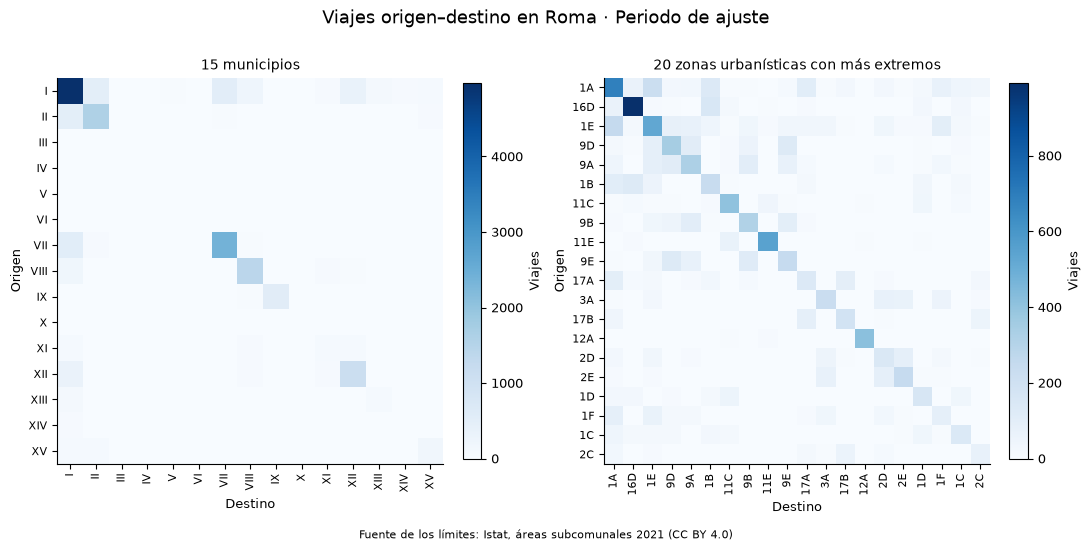

In [3]:
salidas_web = {}
fig, ejes = plt.subplots(ncols=2, figsize=(10.8, 5.4), layout="constrained")
for eje, (clave, zonas) in zip(ejes, zonas_nivel.items()):
    ajuste = matrices[clave, "ajuste"].drop(index=SIN_ZONA, columns=SIN_ZONA)
    if clave == "municipio":
        mostrar = zonas
    else:
        extremos = ajuste.sum(axis=0) + ajuste.sum(axis=1)
        activos = extremos.sort_index().nlargest(20).index
        mostrar = zonas.set_index("codigo").loc[activos].reset_index()

    codigos = mostrar["codigo"].tolist()
    etiquetas = mostrar["etiqueta"].tolist()
    imagen = eje.imshow(ajuste.loc[codigos, codigos], cmap="Blues", interpolation="nearest", vmin=0)
    eje.set_title("15 municipios" if clave == "municipio" else "20 zonas urbanísticas con más extremos")
    eje.set_xlabel("Destino")
    eje.set_ylabel("Origen")
    eje.set_xticks(range(len(codigos)), etiquetas, rotation=90, fontsize=8)
    eje.set_yticks(range(len(codigos)), etiquetas, fontsize=8)
    eje.grid(False)
    fig.colorbar(imagen, ax=eje, shrink=0.8, label="Viajes")

    periodos_web = {}
    for periodo in periodos:
        visible = matrices[clave, periodo].loc[codigos, codigos]
        indicadores = resumen.loc[resumen["nivel"].eq(clave) & resumen["periodo"].eq(periodo)].iloc[0].to_dict()
        periodos_web[periodo] = {
            "resumen": indicadores,
            "matriz": visible.to_numpy(),
            "viajes_visibles": int(visible.to_numpy().sum()),
            "pares": pares_principales[clave, periodo],
        }
    salidas_web[clave] = {
        "zonas": mostrar[["codigo", "nombre", "etiqueta"]],
        "periodos": periodos_web,
    }

fig.suptitle("Viajes origen–destino en Roma · Periodo de ajuste", fontsize=13)
fig.supxlabel("Fuente de los límites: Istat, áreas subcomunales 2021 (CC BY 4.0)", fontsize=8)
guardar_figura(fig, TEMA, "T21_od_administrativa")
exportar("fase1", "t21_od_administrativas", salidas_web)

**Conclusiones.** La web muestra los recuentos de cada corte temporal con el mismo orden de filas y columnas. El resumen del periodo y la tabla de pares principales se calculan con la matriz completa. La diferencia entre el total asignado y el visible en la figura urbana corresponde a viajes con alguno de sus extremos fuera de las veinte zonas seleccionadas.